# The interview question on a new feature, with all six topics: what wins the interview, and does the same page hold for an AI coding assistant?

**Week 4, Monday, chapter 11 of 11, the last case chapter.** It applies all six of the
morning's topics, each taught in its own notebook: *What to measure and why; the proxy test*
(01), *North-star and guardrail metrics* (02), *Leading against lagging indicators* (03),
*Definitions: numerator, denominator, window, exclusions* (04), *Gaming, and definitions that
resist it* (05) and *The metric definition artifact* (06). Level 6 of the case's six: the
interview room, where the same case is asked cold.

**The case.** Uber's Hyderabad city team launched a peak-hour earnings guarantee on Monday
31 August 2026: a floor of Rs 300 per peak online hour, with Uber paying the gap between a
driver's trip earnings and the floor as a top-up.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

**Who needs the answer.** You, in a product or analytics screen, where the question below is
asked cold and a candidate who names one number and stops is screened out.

**The questions on the way.**

1. What does the interviewer ask, and what should a candidate clarify first?
2. Which numbers does a hire-grade answer carry, and does the data hold each one?
3. Where do the zones and the money take the answer?
4. Which line answers each follow-up?
5. Does the same page hold for an AI coding assistant, in your turn?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
zw = pd.read_csv("../data/C2_W04_D01_zone_weeks_STUDENT.csv")
dw["window"] = dw["week_start"].lt("2026-08-31").map({True: "before", False: "after"})
zw["window"] = zw["week_start"].lt("2026-08-31").map({True: "before", False: "after"})
print(f"{len(dw):,} driver-weeks and {len(zw)} zone-weeks, the tables notebooks 07 to 10 read")

12,860 driver-weeks and 144 zone-weeks, the tables notebooks 07 to 10 read


## What does the interviewer ask, and what should a candidate clarify first?

> "Uber launched a peak-hour earnings guarantee for drivers in one city six weeks ago. How would
> you measure whether it is a success?"

A strong candidate asks before naming any number. What was the scheme meant to change: more
drivers online, or riders picked up faster? Who is in it, and who pays? What would count as
harm? Which decision rides on the answer, and against which baseline?

**The trap the interviewer sets.** Peak online hours rose 24 percent. A candidate who names
that number and stops has measured the scheme by what it paid for, chapter 1's proxy test
failed in the first sentence.

A hire-grade answer runs five steps: the goal, one north star with its lines, the guardrails, a
leading input, and the test that would settle cause. This cell computes the number that fills
each step and draws the five steps with their numbers.

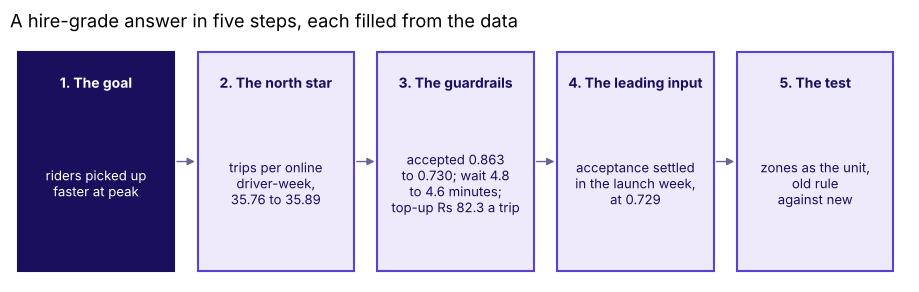

window,before,after
north_star,35.760,35.89
acceptance,0.863,0.73
median_wait,4.800,4.60
topup_per_trip_rs,0.000,82.30


In [2]:
online = dw[dw["peak_online_hours"] > 0]
sums = dw.groupby("window")[["peak_trips", "peak_accepted", "peak_offers", "topup_rs"]].sum()
board = pd.DataFrame({
    "north_star": (online.groupby("window")["peak_trips"].sum() / online.groupby("window").size()).round(2),
    "acceptance": (sums["peak_accepted"] / sums["peak_offers"]).round(3),
    "median_wait": zw.groupby("window")["median_wait_min"].median().round(2),
    "topup_per_trip_rs": (sums["topup_rs"] / sums["peak_trips"]).round(1),
}).loc[["before", "after"]]
wk = dw.groupby("week_start")[["peak_accepted", "peak_offers"]].sum()
launch_acceptance = round(wk.loc["2026-08-31", "peak_accepted"] / wk.loc["2026-08-31", "peak_offers"], 3)
b, a = board.loc["before"], board.loc["after"]
STEPS = [("1. The goal", "riders picked up\nfaster at peak"),
         ("2. The north star", f"trips per online\ndriver-week,\n{b.north_star:.2f} to {a.north_star:.2f}"),
         ("3. The guardrails", f"accepted {b.acceptance:.3f}\nto {a.acceptance:.3f}; wait {b.median_wait}\n"
                               f"to {a.median_wait} minutes;\ntop-up Rs {a.topup_per_trip_rs} a trip"),
         ("4. The leading input", f"acceptance settled\nin the launch week,\nat {launch_acceptance:.3f}"),
         ("5. The test", "zones as the unit,\nold rule\nagainst new")]
fig, ax = plt.subplots(figsize=(11.6, 3.2))
for i, (title, body) in enumerate(STEPS):
    x = i * 2.3
    lit = i == 0
    ax.add_patch(plt.Rectangle((x, 0), 2.0, 2.0, fc=INK if lit else "#EEEAFB", ec=INK if lit else VIOLET, lw=1.5))
    ax.text(x + 1.0, 1.72, title, ha="center", va="center", fontsize=10, fontweight="bold", color="white" if lit else INK)
    ax.text(x + 1.0, 0.8, body, ha="center", va="center", fontsize=9.5, color="white" if lit else INK)
    if i:
        ax.annotate("", xy=(x, 1.0), xytext=(x - 0.3, 1.0), arrowprops={"arrowstyle": "-|>", "color": MUTED})
ax.set_xlim(-0.1, 11.4)
ax.set_ylim(-0.1, 2.15)
ax.axis("off")
ax.set_title("A hire-grade answer in five steps, each filled from the data", loc="left")
plt.show()
board.T

**What happened.** The north star read 35.76 trips per online driver-week before and 35.89
after. Acceptance fell from 0.863 to 0.730 and settled at 0.729 in the launch week itself, the
median wait moved from 4.8 to 4.6 minutes, and the top-up cost Rs 82.3 per completed trip after
the launch, against nothing before.

## Which numbers does a hire-grade answer carry, and does the data hold each one?

**Predict before you run.** Peak online hours rose 24 percent. What did the north star do
across the same two windows?

a) It rose with the hours, by about a quarter.
b) It rose with the trips, by about 3 percent.
c) It barely moved.
d) It fell with trips per hour, by about a sixth.

This cell sets the four numbers a weak answer and a hire-grade answer would read side by side,
each as after over before, with its two values written on its bar.

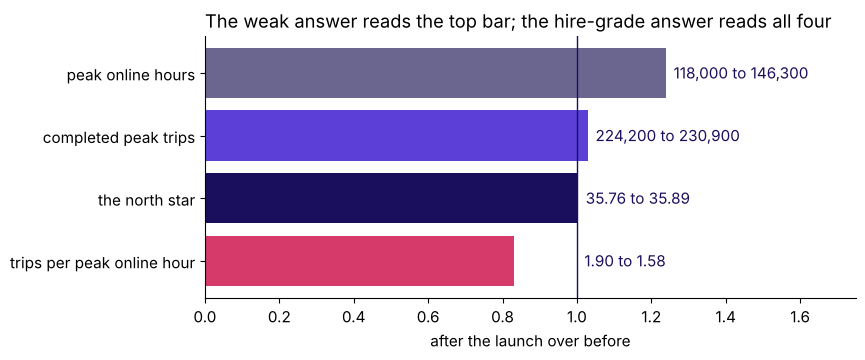

,before,after
peak online hours,118000,146300
completed peak trips,224200,230900
the north star,35.76,35.89
trips per peak online hour,1.9,1.58


In [3]:
hours = dw.groupby("window")["peak_online_hours"].sum()
trips = dw.groupby("window")["peak_trips"].sum()
tph = (trips / hours).round(2)
reads = pd.DataFrame({
    "peak online hours": [hours["before"], hours["after"], f"{hours['before']:,} to {hours['after']:,}"],
    "completed peak trips": [trips["before"], trips["after"], f"{trips['before']:,} to {trips['after']:,}"],
    "the north star": [b.north_star, a.north_star, f"{b.north_star:.2f} to {a.north_star:.2f}"],
    "trips per peak online hour": [tph["before"], tph["after"], f"{tph['before']:.2f} to {tph['after']:.2f}"],
}, index=["before", "after", "label"]).T
ratio = (reads["after"].astype(float) / reads["before"].astype(float)).tolist()
fig, ax = plt.subplots(figsize=(8.4, 3.4))
y = list(range(len(reads)))[::-1]
ax.barh(y, ratio, color=[MUTED, VIOLET, INK, ROSE])
ax.axvline(1.0, color=INK, lw=1)
for yy, r, label in zip(y, ratio, reads["label"]):
    ax.text(max(r, 1.0) + 0.02, yy, label, va="center", color=INK)
ax.set_yticks(y, reads.index)
ax.set_xlim(0, 1.75)
ax.set_xlabel("after the launch over before")
ax.set_title("The weak answer reads the top bar; the hire-grade answer reads all four", loc="left")
plt.show()
reads[["before", "after"]]

**What happened.** The answer is c: the north star moved from 35.76 to 35.89 while hours rose
from 118,000 to 146,300 and trips per peak online hour fell from 1.90 to 1.58. The weak answer
reads the top bar and says the scheme works; the hire-grade answer reads all four and says the
scheme bought hours while the number it exists for barely moved.

## Where do the zones and the money take the answer?

A hire-grade answer then names who moved the number, where, and what each extra trip cost. This
cell finds the idle tail as notebook 08 did, reads the outer zones' wait in each window as the
middle of their 18 zone-week medians, and divides the top-up by the trips it bought: the idle
tail's outer-zone top-up over the extra trips the outer zones fulfilled, and the whole top-up
over the city's extra trips.

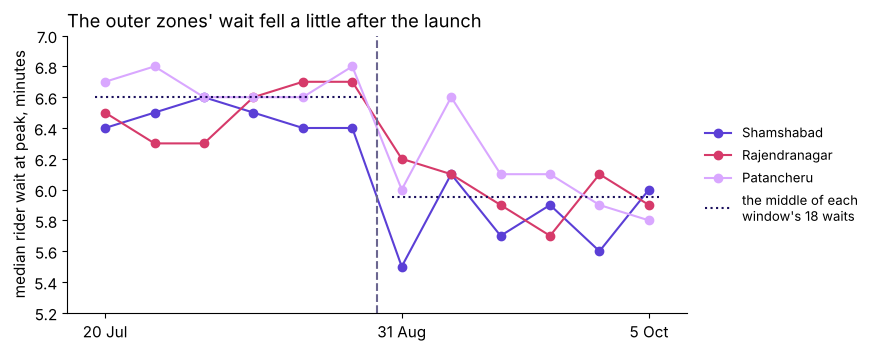

180 drivers in the idle tail; the outer zones' wait 6.6 to 5.95 minutes
the idle tail's outer-zone top-up per extra outer trip: about Rs 46,000
the whole top-up per extra trip across the city: Rs 2,836, over 6,700 extra trips


In [4]:
OUTER = ["Shamshabad", "Rajendranagar", "Patancheru"]
after = dw[dw["window"] == "after"]
per_driver = after.groupby("driver_id")[["peak_trips", "peak_online_hours"]].sum()
idle = set(per_driver.index[per_driver["peak_trips"] / per_driver["peak_online_hours"] < 1.0])
outer = zw[zw["zone"].isin(OUTER)]
outer_wait = outer.groupby("window")["median_wait_min"].median().round(2).loc[["before", "after"]]
o = outer.groupby("window")[["peak_requests", "peak_fulfilled"]].sum()
extra_outer = o.loc["after", "peak_fulfilled"] - o.loc["after", "peak_requests"] * o.loc["before", "peak_fulfilled"] / o.loc["before", "peak_requests"]
idle_outer_topup = after.loc[after["driver_id"].isin(idle) & after["zone_mode"].isin(OUTER), "topup_rs"].sum()
per_extra_outer = int(round(idle_outer_topup / extra_outer, -3))
per_extra_trip = int(round(after["topup_rs"].sum() / (trips["after"] - trips["before"])))
fig, ax = plt.subplots(figsize=(8.0, 3.6))
for zone, colour in zip(OUTER, [VIOLET, ROSE, LAV]):
    z = outer[outer["zone"] == zone].sort_values("week_start")
    ax.plot(range(12), z["median_wait_min"], marker="o", color=colour, label=zone)
for win, (x0, x1) in {"before": (0, 5), "after": (6, 11)}.items():
    ax.hlines(outer_wait[win], x0 - 0.2, x1 + 0.2, color=INK, linestyle=":",
              label="the middle of each\nwindow's 18 waits" if win == "before" else None)
ax.axvline(5.5, color=MUTED, linestyle="--")
ax.set_xticks([0, 6, 11], ["20 Jul", "31 Aug", "5 Oct"])
ax.set_ylim(5.2, 7.0)
ax.set_ylabel("median rider wait at peak, minutes")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9.5)
ax.set_title("The outer zones' wait fell a little after the launch", loc="left")
plt.show()
print(f"{len(idle)} drivers in the idle tail; the outer zones' wait {outer_wait['before']} to {outer_wait['after']} minutes")
print(f"the idle tail's outer-zone top-up per extra outer trip: about Rs {per_extra_outer:,}")
print(f"the whole top-up per extra trip across the city: Rs {per_extra_trip:,}, over {trips['after'] - trips['before']:,} extra trips")

**What happened.** The 180 drivers of the idle tail added hours on fewer trips, most of the new
hours in the three outer zones. There the middle wait fell from 6.6 to 5.95 minutes, so riders
in the thin zones gained a little, and the idle tail's top-up in those zones came to about
Rs 46,000 for each extra trip they fulfilled. Across the city the Rs 1.9 crore came to Rs 2,836
for each of the 6,700 extra trips. That is the decision line: hold the scheme, keep the Rs 300
floor only for weeks that accept at least half their offers, and test the redesign with zones as
the unit.

## Which line answers each follow-up?

| The interviewer pushes | The hire-grade line, from the numbers above |
|---|---|
| "Online hours rose 24 percent; what do you check before you celebrate?" | Trips per online hour and the rider's wait: hours rose 24 percent and trips 3, so the rate fell from 1.90 to 1.58 and waits barely moved |
| "Which guardrail would driver operations fight, and why are they partly right?" | The acceptance floor: some declines are fair, so set it in the gap the data shows, above 0.46 and below 0.78, or 0.43 and 0.67 once an accepted trip later cancelled counts as declined, and test two levels, since on a real city the groups overlap |
| "The drivers control when they log in; what happens to your number?" | Logging in cannot raise it, since each trip needs a rider's request; logging off can, so print the driver count beside the rate |

Notebook 10 ran the third line on the data: doubling the idle tail's hours left the north star
at 35.89, and taking the idle tail's driver-weeks out raised it to 36.88.

## Does the same page hold for an AI coding assistant?

The interviewer's last push moves the question to an AI company: how would you measure an AI
coding assistant without rewarding suggestions that were accepted and then deleted? The gamed
proxy there is suggestions accepted, the way peak online hours were Uber's: a developer can
accept a suggestion and delete it in the next edit. The answer runs on the same seven lines, so
the check is chapter 6's `missing_lines(page)`, copied here from notebook 06 so this notebook
stands alone. The variant is written for this programme and names no company and no figure.

This cell writes the weak answer and Uber's page as pages and draws both, line by line.

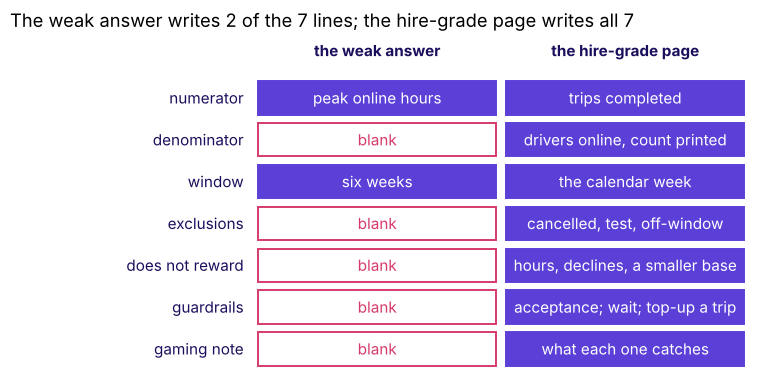

the weak answer: ['denominator', 'exclusions', 'does_not_reward', 'guardrails', 'gaming_note']
the hire-grade page: nothing missing


In [5]:
LINES = ["numerator", "denominator", "window", "exclusions", "does_not_reward", "guardrails", "gaming_note"]

def written(value):
    """A line counts as written when it holds something other than the ____ placeholder."""
    return bool(value) and "____" not in str(value)

def missing_lines(page):
    """The page's blank lines, then every guardrail its gaming note does not say it catches."""
    blank_lines = [line for line in LINES if not written(page.get(line))]
    note = page.get("gaming_note") or {}
    unnamed = [g for g in page.get("guardrails") or [] if not written(note.get(g))]
    return blank_lines + [f"a guardrail that catches nothing named: {g}" for g in unnamed]

uber = {"numerator": "trips completed inside the peak windows, one per paying rider",
        "denominator": "enrolled drivers online at least one peak hour that week, the count printed beside the rate",
        "window": "the calendar week",
        "exclusions": "trips cancelled by either side, test accounts, trips outside the windows",
        "does_not_reward": "hours online, offers declined, a shrinking enrolled base",
        "guardrails": ["offers accepted over offers shown, at or above an acceptance floor",
                       "median rider wait at peak, by zone", "top-up per completed trip"],
        "gaming_note": {"offers accepted over offers shown, at or above an acceptance floor": "catches declining and cherry-picking",
                        "median rider wait at peak, by zone": "catches supply that stops serving riders",
                        "top-up per completed trip": "catches a top-up that runs away from the trips it pays for"}}

weak = {"numerator": "peak online hours", "window": "six weeks"}    # "hours are up 24 percent, so it works"
SHORT = {"numerator": "trips completed", "denominator": "drivers online, count printed",
         "window": "the calendar week", "exclusions": "cancelled, test, off-window",
         "does_not_reward": "hours, declines, a smaller base", "guardrails": "acceptance; wait; top-up a trip",
         "gaming_note": "what each one catches"}
fig, ax = plt.subplots(figsize=(9.6, 4.4))
for r, line in enumerate(LINES):
    y = len(LINES) - 1 - r
    ax.text(-0.15, y, line.replace("_", " "), ha="right", va="center", color=INK)
    for c, (page, text) in enumerate(((weak, weak.get(line) or "blank"), (uber, SHORT[line]))):
        filled = bool(page.get(line))
        ax.add_patch(plt.Rectangle((c * 2.6, y - 0.4), 2.5, 0.8, fc=VIOLET if filled else "white",
                                   ec=VIOLET if filled else ROSE, lw=1.4))
        ax.text(c * 2.6 + 1.25, y, text, ha="center", va="center", color="white" if filled else ROSE)
ax.text(1.25, 7.0, "the weak answer", ha="center", fontweight="bold", color=INK)
ax.text(3.85, 7.0, "the hire-grade page", ha="center", fontweight="bold", color=INK)
ax.set_xlim(-2.6, 5.2)
ax.set_ylim(-0.6, 7.5)
ax.axis("off")
ax.set_title("The weak answer writes 2 of the 7 lines; the hire-grade page writes all 7", loc="left")
plt.show()
for name, page in (("the weak answer", weak), ("the hire-grade page", uber)):
    print(f"{name}: {missing_lines(page) or 'nothing missing'}")

### Your turn: does your page for the AI coding assistant pass the check?

Write the coding assistant's page as seven lines. Its north star is the suggested code still
present at the next commit, per developer with a seat, per week; a commit is a saved change to
the code. Two lines are filled for you. Fill the other five, naming in the gaming note each
guardrail you list and the gaming it catches. In the empty cell below, edit and run:

```python
ai_page = {"numerator": "suggested lines still present at the next commit",
           "denominator": "____",
           "window": "the calendar week",
           "exclusions": "____",
           "does_not_reward": "____",
           "guardrails": ["____"],
           "gaming_note": {"____": "____"}}
```

The check under it runs `missing_lines` on your page and passes when nothing is missing. Then
say which of your lines catches a developer who accepts every suggestion and deletes it in the
next edit.

In [6]:
mine = globals().get("ai_page")
if mine is None:
    print("Store ai_page in the empty cell above, then run this cell again.")
else:
    gaps = missing_lines(mine)
    print("nothing missing: the page holds all seven lines" if not gaps else f"not yet, still missing: {gaps}")

Store ai_page in the empty cell above, then run this cell again.


This cell checks the claims the chapter makes about its own numbers.

In [7]:
check("hours 118,000 to 146,300, trips 224,200 to 230,900, trips per hour 1.90 to 1.58",
      (hours.tolist(), trips.tolist(), tph.tolist()) == ([146300, 118000], [230900, 224200], [1.58, 1.9]))
check("the north star 35.76 to 35.89; acceptance 0.863 to 0.730; the wait 4.8 to 4.6 minutes",
      board["north_star"].tolist() == [35.76, 35.89] and board["acceptance"].tolist() == [0.863, 0.73]
      and board["median_wait"].tolist() == [4.8, 4.6])
check("acceptance settled at 0.729 in the launch week; the top-up cost Rs 82.3 a trip after it",
      launch_acceptance == 0.729 and a.topup_per_trip_rs == 82.3)
check("180 drivers in the idle tail; the outer zones' wait 6.6 to 5.95 minutes",
      len(idle) == 180 and outer_wait.tolist() == [6.6, 5.95])
check("about Rs 46,000 per extra outer trip, and Rs 2,836 per extra trip across the city",
      (per_extra_outer, per_extra_trip) == (46000, 2836))
check("the weak answer writes 2 of the 7 lines, and the hire-grade page all seven",
      len(missing_lines(weak)) == 5 and missing_lines(uber) == [])

PASS hours 118,000 to 146,300, trips 224,200 to 230,900, trips per hour 1.90 to 1.58
PASS the north star 35.76 to 35.89; acceptance 0.863 to 0.730; the wait 4.8 to 4.6 minutes
PASS acceptance settled at 0.729 in the launch week; the top-up cost Rs 82.3 a trip after it
PASS 180 drivers in the idle tail; the outer zones' wait 6.6 to 5.95 minutes
PASS about Rs 46,000 per extra outer trip, and Rs 2,836 per extra trip across the city
PASS the weak answer writes 2 of the 7 lines, and the hire-grade page all seven


## What does chapter 11 answer?

1. Clarify first: what the scheme is for, who is in it and who pays, what counts as harm, and
   which decision rides on the answer against which baseline.
2. The hire-grade answer runs five steps, each filled from the data: riders picked up faster;
   the north star at 35.76 then 35.89; acceptance 0.863 to 0.730, the wait 4.8 to 4.6 minutes
   and Rs 82.3 of top-up a trip; acceptance settled in the launch week; a test by zone.
3. It reads all four bars: hours rose from 118,000 to 146,300 while trips per hour fell from
   1.90 to 1.58 and the north star barely moved.
4. It names the segment and the money: 180 drivers, the outer zones' wait 6.6 to 5.95 minutes
   at about Rs 46,000 per extra outer trip, and Rs 2,836 per extra trip across the city.
5. Each follow-up has a line from the data, and the coding assistant's page runs on the same
   seven lines and the same check.

**The rules.**

- Clarify the goal before naming a number, then name the number the goal needs.
- Read the paid number beside the number it stands for, never alone.
- Close on a decision with its cost, and on the test that would settle cause.

**In the interview.** [S] How would you measure the success of a new feature? ([S] marks a staple asked everywhere, [F] one frequent in GCC and product screens and [D] a differentiator: the curriculum's own calibration for early-career candidates in India.) The six
topics are the skeleton of the answer: the proxy test on the obvious number, a north star with
its guardrails, the leading input, the four lines, the gaming each line resists, and the page
that holds them. The Kahoot follows, and the practice lab's notebook,
`C2_W04_D01_12_kalpa_lab_STUDENT.ipynb`, runs the same method on Kalpa Retail.